# SEM equations · choosing one, and the models it takes

`sweep.sem` has twenty-three equation classes. They all run through the same
`PropSEM(Equation, shape=..., ...)` and the same call, so the choice is about the
physics and about which backend can run it. This notebook:

1. prints the equation table,
2. asks each equation what it needs: `models=`, the default source and receiver, the backend,
3. runs four 2-D equations on one model, two acoustic and two elastic,
4. runs the SH equation on the same model.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

import sweep.sem as sem
from sweep.sem import PropSEM
from sweep.sem.equations import (describe, AcousticPotentialSEM2D,
                                 AcousticSEM2DDeformed, ElasticSEM2DDeformed,
                                 ElasticVSSEM2DDeformed, ElasticSHSEM2DDeformed)
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. The equation table

`describe()` prints one line per equation (`sweep list equations` and
`sweep show <Equation>` print the same from the command line):

In [2]:
print(describe())

  equation                   mesh   D  topo  cpml  flds  records
  --------------------------------------------------------------
  AcousticElasticSEM2D       quad9  2   yes split    20  chi, u_x, u_z
  AcousticPotentialSEM2D     quad9  2   yes   yes     6  chi
  AcousticSEM2D              quad4  2    no   yes     6  u
  AcousticSEM2DDeformed      quad9  2   yes   yes     6  u
  AcousticSEM3D              hex8   3    no   yes     8  u
  AcousticSEM3DDeformed      hex27  3   yes   yes     8  u
  BiotAnisoPermSEM2DDeformed quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  BiotVSSEM2DDeformed        quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  BiotVSSEM3DDeformed        hex27  3   yes   yes    40  v_x, v_y, v_z, p, q_x, q_y, q_z, sigma_xx, sigma_yy, sigma_zz, sigma_xy, sigma_xz, sigma_yz
  ElasticSEM2D               quad4  2    no    NO     4  u_x, u_z
  ElasticSEM2DDeformed       quad9  2   yes   yes    10  u_x, u_z
  E

How to read it:

- **the name**: `Acoustic`, `Elastic`, `Biot` (poroelastic) or `AcousticElastic`
  (fluid-solid); `VS` the first-order velocity-stress form, otherwise second order in
  displacement or pressure; `VTI` / `TTI` transversely isotropic with a vertical / tilted
  axis; `SH` the out-of-plane shear motion; `Visco` with attenuation; `Potential`
  SPECFEM's fluid potential.
- **mesh**: `quad4` / `hex8` are flat meshes; `quad9` / `hex27` follow a `topography`
  (the **topo** column).
- **cpml**: whether the equation has `PropSEM`'s C-PML. The three without it run only as
  a closed box (`abcn=0`); use their `Deformed` or `VS` versions for open models.
- **flds / records**: the number of fields, and the ones a receiver records directly.
  The derived receivers (`p`, `vx`, `vz`, strain, rotation) come on top.

## 2. What each equation needs

A solver reports what it takes: `model_names` is the `models=` list in order, `impl` the
backend (`'c'` the CUDA kernels, `'eager'` PyTorch), and `source_type` / `receiver_type`
the defaults. Building a solver is cheap, so each is built on a small grid:

In [3]:
rows = []
for name, cls in sorted(sem.equations.equation_classes().items()):
    ndim = sem.equations.summary(cls)['ndim']
    shape = (17,) * ndim
    try:
        s = PropSEM(cls, shape=shape, dh=10.0, dt=1e-3, abcn=8, device=device)
        rows.append((name, ', '.join(s.model_names), s.impl,
                     ','.join(s.source_type), ','.join(s.receiver_type)))
    except NotImplementedError:
        rows.append((name, '(no C-PML: abcn=0 only)', '', '', ''))

print(f"{'equation':28s} {'models=':42s} {'impl':6s} {'source':12s} receivers")
for r in rows:
    print(f'{r[0]:28s} {r[1]:42s} {r[2]:6s} {r[3]:12s} {r[4]}')

equation                     models=                                    impl   source       receivers
AcousticElasticSEM2D         vp, vs, rho                                c      chi          p,vx,vz
AcousticPotentialSEM2D       vp                                         c      chi          p
AcousticSEM2D                vp                                         eager  u            u
AcousticSEM2DDeformed        vp                                         eager  u            u
AcousticSEM3D                vp                                         c      u            u
AcousticSEM3DDeformed        vp                                         c      u            u
BiotAnisoPermSEM2DDeformed   H, mu, C, M, rho, rho_f, m, b_xx, b_xz, b_zz c      sxx,szz      v_x,v_z
BiotVSSEM2DDeformed          H, mu, C, M, rho, rho_f, m, b              c      sxx,szz      v_x,v_z
BiotVSSEM3DDeformed          H, mu, C, M, rho, rho_f, m, b              c      sxx,syy,szz  v_x,v_y,v_z
ElasticSEM2D          

`impl='c'` runs on a GPU for every equation but the six that show `eager` here; those run
compiled PyTorch, on the GPU or the CPU. Acoustic models are `[vp]` with a constant
`density=` (default 1000), elastic ones `[vp, vs, rho]`, plus Thomsen's parameters for
VTI and TTI and quality factors for the visco-elastic classes. Biot takes eight
poroelastic coefficients, from `sweep.equations.biot.biot_from_rock`.

A shortlist for 2-D:

| you want | use | backend |
| --- | --- | --- |
| acoustic modelling / FWI, fast, many shots | `AcousticPotentialSEM2D` | `'c'` |
| acoustic, simplest pressure form | `AcousticSEM2DDeformed` (`AcousticSEM2D` if flat) | eager |
| elastic modelling / FWI, fast | `ElasticSEM2DDeformed` | `'c'` |
| elastic with stress sources / velocity-stress | `ElasticVSSEM2DDeformed` | `'c'` |
| SH (out-of-plane) waves | `ElasticSHSEM2DDeformed` | eager |
| VTI or tilted TI elastic | `ElasticVTISEM2DDeformed`, `ElasticTTISEM2DDeformed` | `'c'` |
| attenuation, velocity-stress | `ViscoElasticVSSEM2DDeformed` | `'c'` |
| attenuation, acoustic or displacement form | `ViscoAcousticPotentialSEM2D`, `ViscoElasticSEM2DDeformed` | eager |
| water over an elastic sea floor | `AcousticElasticSEM2D` | `'c'` |
| poroelastic | `BiotVSSEM2DDeformed` (`ViscoBiotVSSEM2DDeformed` with an attenuating frame) | `'c'` |

The attenuating classes have their own notebook, [SEM attenuation](../49_sem_attenuation/).

## 3. Four equations on one model

A two-layer model with a free surface on top: a source 200 m deep and a line of
receivers 20 m deep. The acoustic equations take `vp` only, the elastic ones
`vp, vs, rho`.

In [4]:
dh, n_order = 10.0, 4
shape = (97, 193)                          # 960 m x 1920 m, 24 x 48 elements
f0, dt, nt = 8.0, 0.8e-3, 1500

vp  = torch.full(shape, 1800.0); vp[48:]  = 2500.0
vs  = torch.full(shape, 1000.0); vs[48:]  = 1400.0
rho = torch.full(shape, 2000.0); rho[48:] = 2200.0
vp, vs, rho = (m.to(device) for m in (vp, vs, rho))

wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[shape[1] // 2, 20]])                      # [ix, iz]
rx = np.arange(4, shape[1] - 4, 2)
rec = np.stack([rx, np.full_like(rx, 2)], axis=1)[None]   # (1, nrec, 2)

The acoustic equations record the pressure `p`, the elastic ones the vertical particle
velocity of a vertical point force, `['vz']`. Everything else is the same call:

In [5]:
runs = {
    'AcousticPotentialSEM2D': (AcousticPotentialSEM2D, [vp],          ['p']),
    'AcousticSEM2DDeformed':  (AcousticSEM2DDeformed,  [vp],          ['p']),
    'ElasticSEM2DDeformed':   (ElasticSEM2DDeformed,   [vp, vs, rho], ['vz']),
    'ElasticVSSEM2DDeformed': (ElasticVSSEM2DDeformed, [vp, vs, rho], ['vz']),
}
records = {}
for name, (eq, models, rtype) in runs.items():
    kw = dict(source_type=['vz']) if 'Elastic' in name else {}
    solver = PropSEM(eq, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=40,
                     free_surface=True, f_dominant=f0, receiver_type=rtype,
                     device=device, **kw)
    with torch.no_grad():
        records[name] = solver(wavelet, src, rec, models=models)[0, :, :, 0].cpu().numpy()
    print(f'{name:24s} impl={solver.impl}')

AcousticPotentialSEM2D   impl=c


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 97x193 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


AcousticSEM2DDeformed    impl=eager


ElasticSEM2DDeformed     impl=c


ElasticVSSEM2DDeformed   impl=c


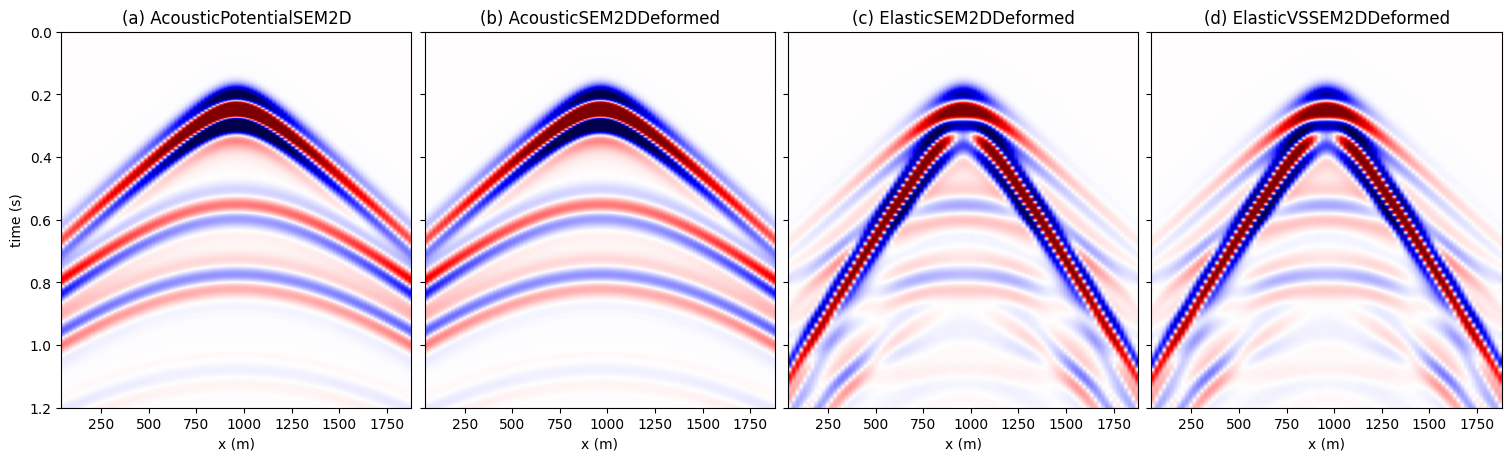

In [6]:
def show(ax, g, title):
    v = np.percentile(np.abs(g), 98)
    ax.imshow(g, cmap='seismic', vmin=-v, vmax=v, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True, constrained_layout=True)
for ax, lab, (name, g) in zip(axes, 'abcd', records.items()):
    show(ax, g, f'({lab}) {name}')
axes[0].set_ylabel('time (s)')
plt.show()

The two acoustic records show the direct wave, the reflection from the layer boundary at
480 m, and the free-surface ghosts and multiples; the two elastic ones add converted and
shear waves and the Rayleigh wave along the surface. Within each pair the waveforms are the
same. The scales are not: each equation has its own source normalization, and the potential
form's pressure carries the bulk modulus `rho vp^2` at the source (SPECFEM's convention), so
in an inversion the wavelet is scaled to the data.

## 4. SH waves

`ElasticSHSEM2DDeformed` solves for the out-of-plane displacement `u_y` of a medium that
does not change along y (SPECFEM2D's `P_SV = .false.`). It takes `[vs, rho]`, its source is
a force along y, and it records `u_y` or its velocity `vy`. On the same model, next to the
vertical force of `ElasticSEM2DDeformed`:

models: ['vs', 'rho']   source: ['u_y']   impl: eager


sweep: torch.compile is compiling the ElasticSHSEM2DDeformed step for a 97x193 grid


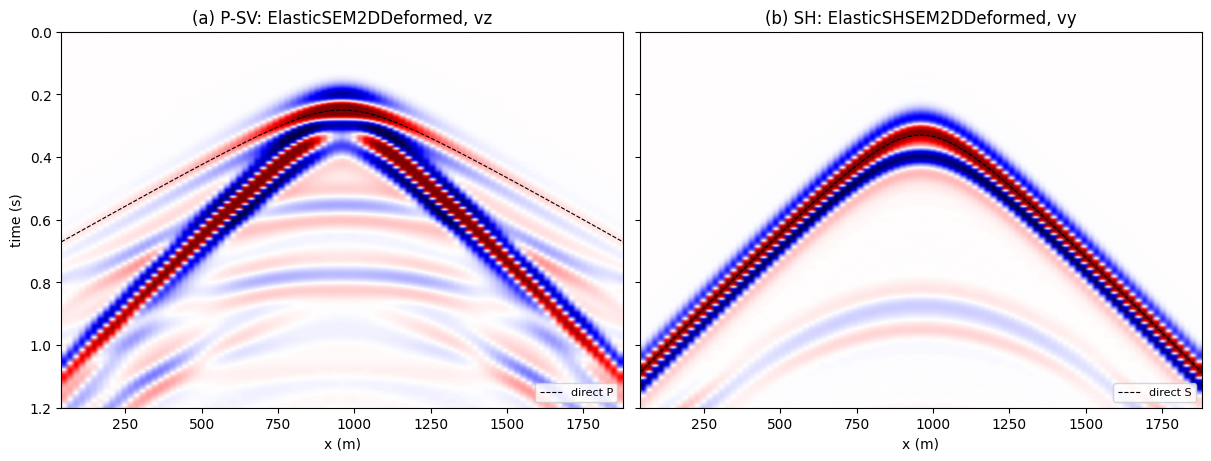

In [7]:
sh = PropSEM(ElasticSHSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=40,
             free_surface=True, f_dominant=f0, receiver_type=['vy'], device=device)
print('models:', sh.model_names, '  source:', sh.source_type, '  impl:', sh.impl)
with torch.no_grad():
    vy = sh(wavelet, src, rec, models=[vs, rho])[0, :, :, 0].cpu().numpy()

offset = (rx - src[0, 0]) * dh
depth = (src[0, 1] - rec[0, 0, 1]) * dh                 # 180 m from the source up to the receivers
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
for ax, g, title, v, wave in [
        (axes[0], records['ElasticSEM2DDeformed'], '(a) P-SV: ElasticSEM2DDeformed, vz', 1800.0, 'direct P'),
        (axes[1], vy, '(b) SH: ElasticSHSEM2DDeformed, vy', 1000.0, 'direct S')]:
    show(ax, g, title)
    ax.plot(rx * dh, np.hypot(offset, depth) / v + 1.2 / f0, 'k--', lw=0.8, label=wave)
    ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('time (s)')
plt.show()

The SH record holds S waves only: the direct S wave (dashed, 1000 m/s from the
source 180 m below the receivers) and, from about 0.9 s at zero offset, the
reflection from the layer boundary at 480 m. The P wave and the Rayleigh wave are
in-plane motion and do not appear. The class runs on eager, flat or under a
topography, and takes `interfaces=` ([SEM mesh and time step](../50_sem_mesh_and_time_step/)).

## Summary

- Pick the equation by physics (acoustic, elastic, SH, anisotropic, attenuating,
  fluid-solid, poroelastic) and by backend: the `impl='c'` ones are the fast choice for
  many shots and for inversion; the rest run eager.
- `solver.model_names` is the `models=` list, in order; models are grid tensors of `shape`.
- Changing the equation is a change of the class and of `models=`; the call and the record
  layout `(nshots, nt, nrec, ncomp)` stay the same.

Next: [SEM sources and receivers · positions, types and shots](../52_sem_sources_and_receivers/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="51_sem_equations_and_models.ipynb" download><code>51_sem_equations_and_models.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/51_sem_equations_and_models.ipynb">view on GitHub</a></p>